In [ ]:
%pip install langchain-huggingface sentence-transformers

In [ ]:
%pip install -U langchain-community

In [ ]:
%pip install pypdf

In [ ]:
%pip install langchain-huggingface sentence-transformers

In [10]:
%pip install -U langchain-community
%pip install pypdf
%pip install langchain-huggingface sentence-transformers
%pip install faiss-cpu
%pip install langchain-text-splitters


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
   ---------------------------------------- 0.0/16.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/16.2 MB ? eta -:--:--
    --------------------------------------- 0.3/16.2 MB ? eta -:--:--
   - -------------------------------------- 0.5/16.2 MB 882.6 kB/s eta 0:00:18
   - -------------------------------------- 0.5/16.2 MB 882.6 kB/s eta 0:00:18
   - -------------------------------------- 0.8/16.2 MB 882.6 kB/s eta 0:00:18
   - -------------------------------------- 0.8/16.2 MB 882.6 kB/s eta 0:00:18
   -- ------------------------------------- 1.0/16.2 MB 739.8 kB/s eta 0:00:21
   -- ------------------------------------- 1.0/16.2 MB 739.8 kB/s eta 0:00:21
   --- ------------------------------------ 1.3/16.2 MB 771.6 kB/s eta 0:00:20
   ---- -------------------------------

In [ ]:
# from langchain_openai import ChatOpenAI, OpenAIEmbeddings
# from langchain_google_genai import ChatGoogleGenerativeAI
# from langchain_google_genai import GoogleGenerativeAIEmbeddings
from langchain_groq import ChatGroq
from langchain_huggingface import HuggingFaceEmbeddings
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, BaseMessage
from langgraph.prebuilt import ToolNode, tools_condition

f:\projects\Agentic AI Chat\langgraph-env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\LENOVO\AppData\Local\Temp\ipykernel_5576\3837171752.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [2]:
load_dotenv()

True

In [3]:
llm = ChatGroq(
    model="llama-3.3-70b-versatile",
    temperature=0
)

In [4]:
loader = PyPDFLoader("my_paper.pdf")
docs = loader.load()

In [5]:
docs

[Document(metadata={'producer': 'ImageMagick 6.9.0-6 Q8 x86_64 2015-02-23 http://www.imagemagick.org', 'creator': 'PyPDF', 'creationdate': 'D:20170625020547', 'title': '1498381536222425112-US20140350961A1', 'moddate': 'D:20170625020547', 'source': 'my_paper.pdf', 'total_pages': 16, 'page': 0, 'page_label': '1'}, page_content="US 20140350961A1 (19) United States (12) Patent Application Publication (10) Pub. No.: US 2014/0350961 A1 Csurka et al. (43) Pub. Date: Nov. 27, 2014 (54) TARGETED SUMMARIZATION OF (52) U.S. Cl. MEDICAL DATA BASED ON MIPLCT CPC .................................... G06F 19/322 (2013.01) QUERIES USPC .............................................................. 705/3 (71) Applicant: Xerox Corporation, Norwalk, CT (US) (57) ABSTRACT (72) Inventors: Gabriela Csurka, Crolles (FR); Mario Agustin Ricardo Jarmasz, Meylan A system and method for targeted Summarization of a (FR); Florent C. Perronnin, Domene patient’s electronic medical records are provided. The system (FR

In [6]:
len(docs)

16

In [7]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = splitter.split_documents(docs)

In [8]:
len(chunks)

121

In [12]:
embeddings = HuggingFaceEmbeddings(model_name="all-MiniLM-L6-v2")
vector_store = FAISS.from_documents(chunks, embeddings)


f:\projects\Agentic AI Chat\langgraph-env\Lib\site-packages\huggingface_hub\file_download.py:141: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\LENOVO\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
Loading weights: 100%|██████████| 103/103 [00:00<00:00, 4028.28it/s]


In [13]:
embeddings = HuggingFaceEmbeddings(
    model="all-MiniLM-L6-v2"
)
vector_store = FAISS.from_documents(chunks, embeddings)
vector_store.save_local("faiss_index")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6013.88it/s]


In [14]:
vector_store

In [15]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [18]:
ans = retriever.invoke("what is the main Abstract?")
ans

[Document(id='27825726-3dc9-40c2-b516-33ffbbb833c6', metadata={'producer': 'ImageMagick 6.9.0-6 Q8 x86_64 2015-02-23 http://www.imagemagick.org', 'creator': 'PyPDF', 'creationdate': 'D:20170625020547', 'title': '1498381536222425112-US20140350961A1', 'moddate': 'D:20170625020547', 'source': 'my_paper.pdf', 'total_pages': 16, 'page': 10, 'page_label': '11'}, page_content='types of concepts that are linked together. As example, the concepts may include parts and Sub-parts of the human body, biological functions, diseases, syndromes, and other medical conditions, pharmacological Substances, including general classes of medicines and specific examples of medicines, and other methods of treatment, and the like. As an example ontology, the Unified Medical Language System (UMLS, see http://www.nlm.nih.gov/research/umls/) designed by the US National Library of Medicine, may be employed. See, for example, Olivier Bodenreider, “The Unified Medical Lan guage System (UMLS): integrating biomedical t

In [19]:
@tool
def rag_tool(query: str) -> str:
    """
    Retrieve relevant information from the PDF document.

    Use this tool when the user asks factual or conceptual questions
    that may be answered using the stored PDF documents.

    Args:
        query: The question or search query used to retrieve PDF content.
    """

    documents = retriever.invoke(query)

    if not documents:
        return "No relevant information was found in the PDF."

    formatted_documents = []

    for index, document in enumerate(documents, start=1):
        source = document.metadata.get("source", "Unknown source")
        page = document.metadata.get("page", "Unknown page")

        formatted_documents.append(
            f"Document {index}\n"
            f"Source: {source}\n"
            f"Page: {page}\n"
            f"Content: {document.page_content}"
        )

    return "\n\n".join(formatted_documents)

In [20]:
tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools)

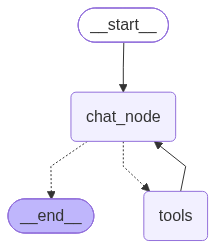

In [21]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]
# graph nodes
def chat_node(state: ChatState):
    """LLM node that may answer or request a tool call."""
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools)  # Executes tool calls
# graph structure
graph = StateGraph(ChatState)
graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)
graph.add_edge(START, "chat_node")

# If the LLM asked for a tool, go to ToolNode; else finish
graph.add_conditional_edges("chat_node", tools_condition)

graph.add_edge("tools", "chat_node")  
chatbot = graph.compile()

chatbot

In [22]:
# Regular chat
result = chatbot.invoke({"messages": [HumanMessage(content="Hello")]})

print(result["messages"][-1].content)

Hello. How can I help you today?


In [23]:
# Regular chat
result = chatbot.invoke({"messages": [HumanMessage(content="Using the pdf notes, explain all my notes in a concise way and what are main points in the notes?")]})

print(result["messages"][-1].content)

The main points in the notes are:

1. The system and method for summarization of medical data are based on the principle that relevant information depends on the context.
2. The system uses a conceptual model for organizing data called AORTIS to summarize and visualize medical information.
3. The system can generate a graphical rendition of the summarized information, which can be used to help healthcare providers quickly understand a patient's medical history and relevant information.
4. The system can handle highly heterogeneous information, including text, audio, and visual information, and can summarize and visualize this information in a way that is relevant to the healthcare provider's context.
5. The system uses implicit queries to retrieve relevant information from a patient's personal health record (PHR) data, and can visualize the summarized information in a way that is easy to understand.

Overall, the notes appear to be discussing a system and method for summarizing and vis

In [28]:
print(result["messages"][-1].content)

The main points in the notes are:

1. The system and method for summarization of medical data are based on the principle that relevant information depends on the context.
2. The system uses a conceptual model for organizing data called AORTIS to summarize and visualize medical information.
3. The system can generate a graphical rendition of the summarized information, which can be used to help healthcare providers quickly understand a patient's medical history and relevant information.
4. The system can handle highly heterogeneous information, including text, audio, and visual information, and can summarize and visualize this information in a way that is relevant to the healthcare provider's context.
5. The system uses implicit queries to retrieve relevant information from a patient's personal health record (PHR) data, and can visualize the summarized information in a way that is easy to understand.

Overall, the notes appear to be discussing a system and method for summarizing and vis